In [ ]:
import cv2
import openslide
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt

os.chdir(".../hoefflin2026spatial")

In [ ]:
he_image = tifffile.imread("IDHO03_HE.ome.tif")
mx_image = tifffile.imread("IDHO03.ome.tif")

In [60]:
dapi_arr = mx_image[0]

# Normalise to uint8 for OpenCV
dapi_norm = cv2.normalize(dapi_arr.astype(np.float32), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
print("DAPI shape:", dapi_norm.shape)


DAPI shape: (7008, 6304)


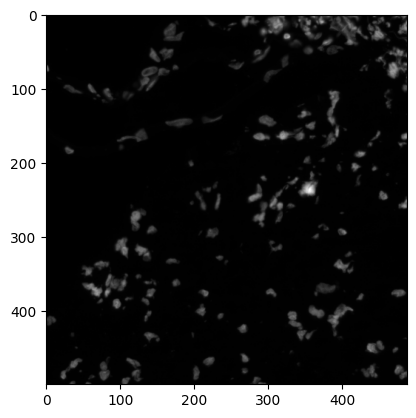

In [61]:
plt.imshow(dapi_norm[4000:4500, 512:1000], cmap='gray')

In [ ]:
# Read H&E from the WSI slide at the 2nd highest resolution (level 1, ~0.5 um/px)
he_image = tifffile.imread("IDHO03_HE.ome.tif", level=1)

dapi_h, dapi_w = dapi_norm.shape
he_h, he_w = he_image.shape[:2]

# use 2nd highest resolution level of H&E image
print(f"Using he: {he_w}x{he_h}  |  DAPI: {dapi_w}x{dapi_h}")

Using he: 6624x7104  |  DAPI: 6304x7008


In [63]:
# Read full level as RGB
he_rgb = he_image
he_gray = cv2.cvtColor(he_rgb, cv2.COLOR_RGB2GRAY)
print("H&E grayscale shape:", he_gray.shape)

H&E grayscale shape: (7104, 6624)


In [64]:
# SIFT-based coregistration: DAPI (fixed) <-> H&E grayscale (moving)
# Invert DAPI so bright nuclei become dark, matching H&E appearance
dapi_inv = cv2.bitwise_not(dapi_norm)

sift = cv2.SIFT_create()

kp_dapi, desc_dapi = sift.detectAndCompute(dapi_inv, None)
kp_he, desc_he = sift.detectAndCompute(he_gray, None)
print(f"Keypoints — DAPI: {len(kp_dapi)}, H&E: {len(kp_he)}")

# FLANN matcher
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)

matches = flann.knnMatch(desc_dapi, desc_he, k=2)

# Lowe's ratio test
good = [m for m, n in matches if m.distance < 0.75 * n.distance]
print(f"Good matches after ratio test: {len(good)}")

# Compute homography (maps H&E -> DAPI space) with RANSAC
if len(good) >= 4:
    src_pts = np.float32([kp_he[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_dapi[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    inliers = int(mask.sum())
    print(f"Homography inliers: {inliers}/{len(good)}")
    print("Homography matrix:\n", H)
else:
    raise RuntimeError(f"Not enough good matches ({len(good)}) to compute homography.")


Keypoints — DAPI: 51306, H&E: 162888
Good matches after ratio test: 2270
Homography inliers: 898/2270
Homography matrix:
 [[ 9.80937709e-01  4.68444157e-03 -3.05030087e+01]
 [-4.74918235e-03  9.80928072e-01  4.97992842e+01]
 [ 2.15226130e-08 -1.28380145e-08  1.00000000e+00]]


In [65]:
# --- Non-rigid refinement: Thin-Plate-Spline on top of the homography ---
# A single global homography can't capture local tissue deformation between
# serial DAPI/H&E sections (stretching, tearing, non-uniform shrinkage during
# processing). Refine it with a smooth Thin-Plate-Spline warp fitted to the
# RANSAC-inlier SIFT correspondences we already have, so the final transform
# is accurate at the pixel level, not just globally affine/projective.
#
# Implemented directly with numpy (closed-form TPS solve) rather than
# cv2.createThinPlateSplineShapeTransformer, which lives in opencv-contrib's
# "shape" module and isn't available in a plain opencv-python install.

H_inv = np.linalg.inv(H)

inlier_mask = mask.ravel().astype(bool)
src_inliers = src_pts[inlier_mask].reshape(-1, 2)   # H&E raw pixel coords
dst_inliers = dst_pts[inlier_mask].reshape(-1, 2)   # DAPI pixel coords
n_inliers = len(src_inliers)
print(f"TPS control points (RANSAC inliers): {n_inliers}")
if n_inliers < 20:
    print("WARNING: few inliers -- TPS may overfit/extrapolate poorly away from "
          "the control points. Consider loosening the ratio test or adding more features.")

# Pre-warp the H&E inlier points with the homography so the TPS only needs to
# correct the residual *local* deformation, not the whole global transform.
src_inliers_h = cv2.perspectiveTransform(src_inliers.reshape(-1, 1, 2), H).reshape(-1, 2)


def _dedup(P, Q):
    """Merge (near-)identical points, averaging their targets. Needed because
    SIFT correspondences can be many-to-one (several keypoints matching to the
    same point, common in repetitive tissue texture), which makes exact TPS
    interpolation ill-posed -- the linear system below becomes singular."""
    P = np.asarray(P, dtype=np.float64)
    Q = np.asarray(Q, dtype=np.float64)
    keys, inverse = np.unique(np.round(P, 2), axis=0, return_inverse=True)
    Q_sum = np.zeros((len(keys), 2))
    counts = np.zeros(len(keys))
    np.add.at(Q_sum, inverse, Q)
    np.add.at(counts, inverse, 1)
    return keys, Q_sum / counts[:, None]


_, _dedup_check = _dedup(src_inliers_h, dst_inliers)
print(f"Unique control points after merging duplicates: {len(_dedup_check)} / {n_inliers}")


def _tps_fit(P, Q, smoothing=1e-4):
    """Fit a 2D thin-plate-spline mapping control points P -> Q. Deduplicates
    (near-)identical source points first and adds a small relative smoothing
    term for numerical stability (and robustness to keypoint localization
    noise -- an exact interpolant would otherwise fit that noise too).
    Returns (P, w, a): P is the (deduplicated) control points used for
    evaluation, w are the RBF weights (N, 2), a are the affine coeffs (3, 2)."""
    P, Q = _dedup(P, Q)
    n = len(P)
    d = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    with np.errstate(divide="ignore", invalid="ignore"):
        K = np.where(d > 0, d ** 2 * np.log(d), 0.0)
    K += smoothing * np.mean(np.abs(K)) * np.eye(n)
    P_aug = np.hstack([np.ones((n, 1)), P])
    L = np.zeros((n + 3, n + 3))
    L[:n, :n] = K
    L[:n, n:] = P_aug
    L[n:, :n] = P_aug.T
    rhs = np.zeros((n + 3, 2))
    rhs[:n] = Q
    coeffs = np.linalg.solve(L, rhs)
    return P, coeffs[:n], coeffs[n:]


def _tps_apply(pts, P, w, a, chunk=20000):
    """Evaluate a fitted TPS at arbitrary points, chunked to bound memory
    (the dense distance matrix is O(n_points * n_control_points))."""
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    out = np.empty_like(pts)
    for i in range(0, len(pts), chunk):
        seg = pts[i:i + chunk]
        d = np.sqrt(((seg[:, None, :] - P[None, :, :]) ** 2).sum(-1))
        with np.errstate(divide="ignore", invalid="ignore"):
            U = np.where(d > 0, d ** 2 * np.log(d), 0.0)
        out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w
    return out


# --- Honest accuracy check: fit on a random 80% subset, evaluate on the held-out 20% ---
# (TPS interpolates its control points exactly, so checking on the same points
# used to fit it would trivially show ~0 error -- this held-out split gives a
# realistic estimate of how well it generalises between keypoints.)
rng = np.random.default_rng(0)
perm = rng.permutation(n_inliers)
n_test = max(10, int(0.2 * n_inliers))
test_idx, train_idx = perm[:n_test], perm[n_test:]

probe_P, probe_w, probe_a = _tps_fit(src_inliers_h[train_idx], dst_inliers[train_idx])
probe_pred = _tps_apply(src_inliers_h[test_idx], probe_P, probe_w, probe_a)

err_h_holdout = np.linalg.norm(src_inliers_h[test_idx] - dst_inliers[test_idx], axis=1)
err_tps_holdout = np.linalg.norm(probe_pred - dst_inliers[test_idx], axis=1)
print(f"[Held-out keypoints, n={n_test}] residual error, homography-only vs. +TPS:")
print(f"  Homography only : mean={err_h_holdout.mean():.2f}px  median={np.median(err_h_holdout):.2f}px  max={err_h_holdout.max():.2f}px")
print(f"  Homography + TPS: mean={err_tps_holdout.mean():.2f}px  median={np.median(err_tps_holdout):.2f}px  max={err_tps_holdout.max():.2f}px")

# --- Production transforms: refit on ALL inliers for the best final field ---
tps_fwd_P, tps_fwd_w, tps_fwd_a = _tps_fit(src_inliers_h, dst_inliers)   # homography-aligned H&E -> DAPI
tps_inv_P, tps_inv_w, tps_inv_a = _tps_fit(dst_inliers, src_inliers_h)   # DAPI -> homography-aligned H&E


def he_to_dapi(pts_he_raw):
    """Map raw H&E pixel coords (x, y) -> DAPI pixel coords: homography + TPS."""
    pts = np.asarray(pts_he_raw, dtype=np.float64).reshape(-1, 1, 2)
    pts_h = cv2.perspectiveTransform(pts, H).reshape(-1, 2)
    return _tps_apply(pts_h, tps_fwd_P, tps_fwd_w, tps_fwd_a)


def dapi_to_he(pts_dapi):
    """Map DAPI pixel coords (x, y) -> raw H&E pixel coords: TPS + inverse homography."""
    pts_h = _tps_apply(pts_dapi, tps_inv_P, tps_inv_w, tps_inv_a)
    pts_h = pts_h.reshape(-1, 1, 2)
    pts_he = cv2.perspectiveTransform(pts_h, H_inv)
    return pts_he.reshape(-1, 2)


TPS control points (RANSAC inliers): 898
Unique control points after merging duplicates: 834 / 898
[Held-out keypoints, n=179] residual error, homography-only vs. +TPS:
  Homography only : mean=1.00px  median=0.96px  max=2.70px
  Homography + TPS: mean=0.96px  median=0.85px  max=3.73px


/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: divide by zero encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w
/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: overflow encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w
/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: invalid value encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w


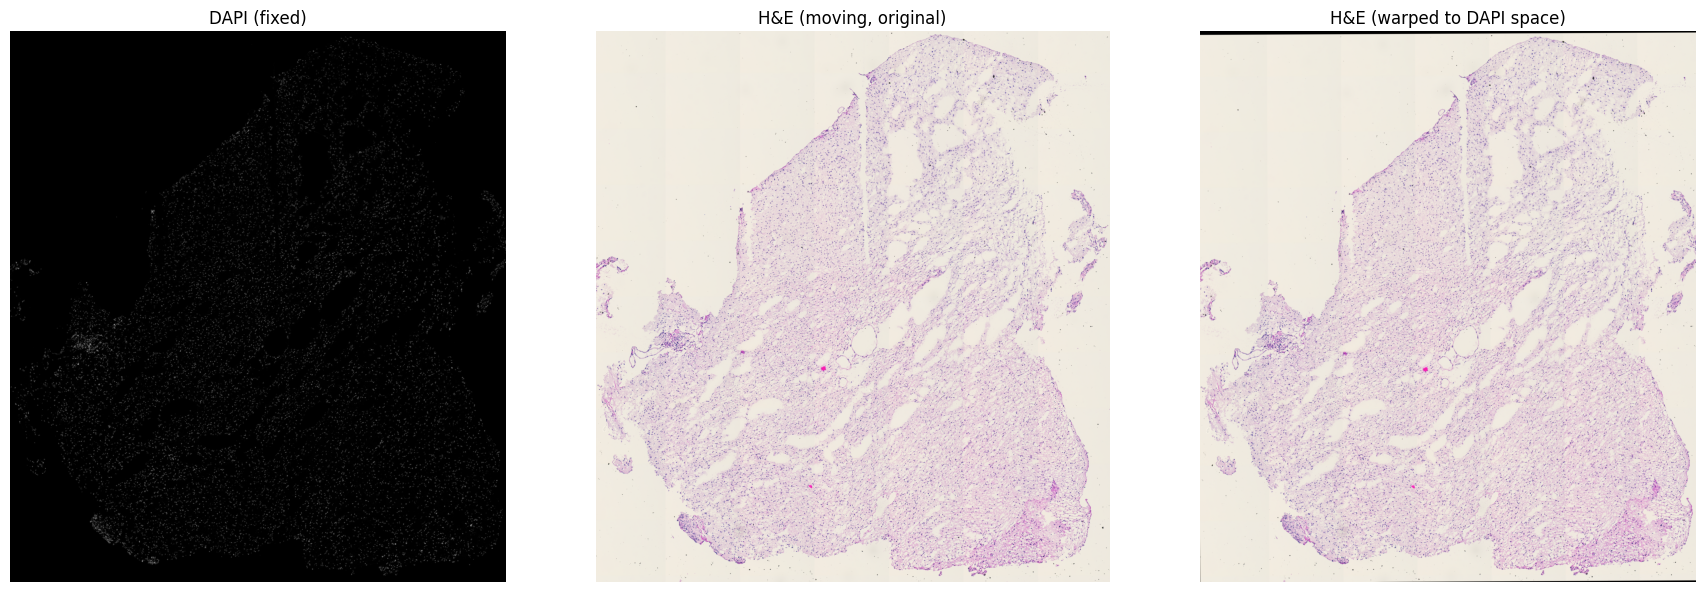

In [66]:
# Warp H&E RGB into DAPI space and do a quick visual check
# OpenCV warpPerspective requires all dimensions < SHRT_MAX (32767).
# Scale both images down by factor of 2 for the warp; adjust H accordingly.
import matplotlib.pyplot as plt

SCALE = 0.5
dapi_vis_w = int(dapi_w * SCALE)
dapi_vis_h = int(dapi_h * SCALE)

# Scale matrix: S * H * S_inv maps scaled H&E -> scaled DAPI space
S = np.array([[SCALE, 0, 0],
              [0, SCALE, 0],
              [0,      0, 1]], dtype=np.float64)
S_inv = np.linalg.inv(S)
H_scaled = S @ H @ S_inv

he_rgb_small = cv2.resize(he_rgb, (int(he_w * SCALE), int(he_h * SCALE)))
dapi_small   = cv2.resize(dapi_norm, (dapi_vis_w, dapi_vis_h))

he_warped = cv2.warpPerspective(he_rgb_small, H_scaled, (dapi_vis_w, dapi_vis_h))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(dapi_small, cmap="gray")
axes[0].set_title("DAPI (fixed)")
axes[1].imshow(he_rgb_small)
axes[1].set_title("H&E (moving, original)")
axes[2].imshow(he_warped)
axes[2].set_title("H&E (warped to DAPI space)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [67]:
# Save homography (DAPI -> H&E is H_inv) and its inverse to text files
H_inv = np.linalg.inv(H)

out_path = "P87_8967_16_homography_3dh.txt"
with open(out_path, "w") as f:
    f.write("# Homography H: maps H&E pixel coords -> DAPI pixel coords\n")
    np.savetxt(f, H, fmt="%.10e")
    f.write("\n# Inverse H_inv: maps DAPI pixel coords -> H&E pixel coords\n")
    np.savetxt(f, H_inv, fmt="%.10e")

print(f"Saved to {out_path}")
print("H:\n", H)
print("H_inv:\n", H_inv)


Saved to P87_8967_16_homography_3dh.txt
H:
 [[ 9.80937709e-01  4.68444157e-03 -3.05030087e+01]
 [-4.74918235e-03  9.80928072e-01  4.97992842e+01]
 [ 2.15226130e-08 -1.28380145e-08  1.00000000e+00]]
H_inv:
 [[ 1.01940847e+00 -4.86779534e-03  3.13374381e+01]
 [ 4.93659658e-03  1.01941850e+00 -5.06157306e+01]
 [-2.18769578e-08  1.31920772e-08  9.99998676e-01]]


/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: divide by zero encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w
/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: overflow encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w
/var/folders/b4/0_1bc3z568d7bmf_6y_wwxzh0000gn/T/ipykernel_3411/477361954.py:81: RuntimeWarning: invalid value encountered in matmul
  out[i:i + chunk] = a[0] + seg @ a[1:] + U @ w


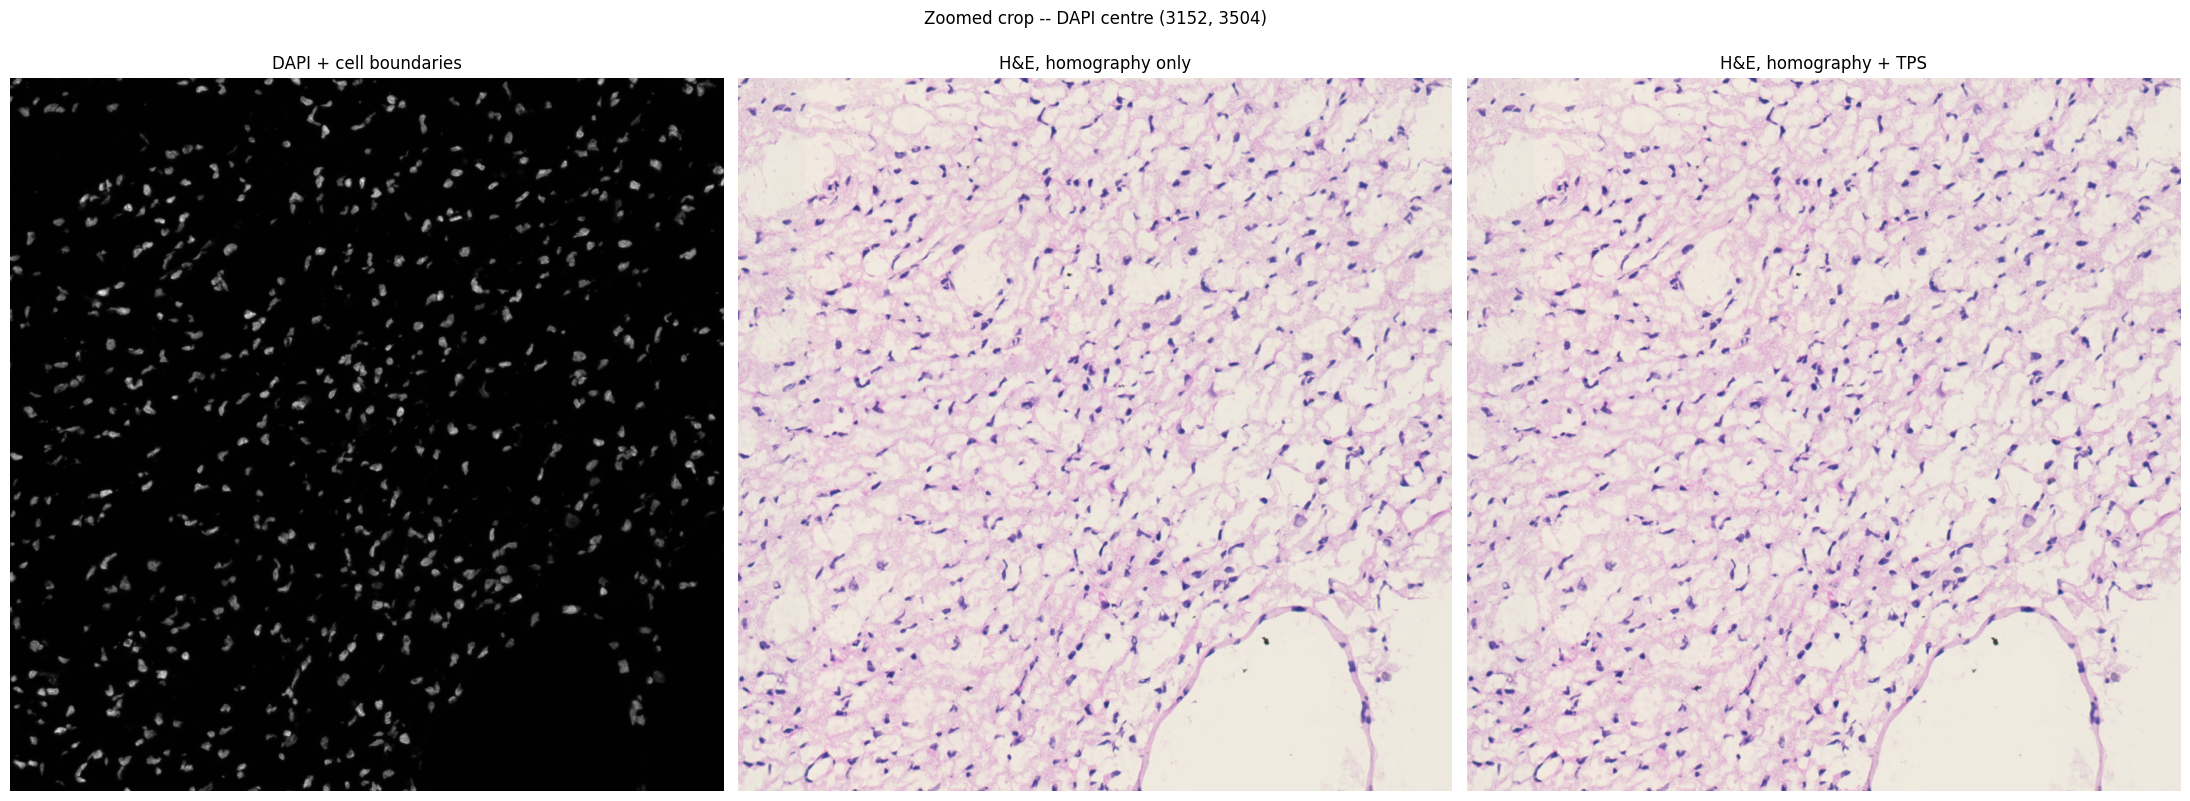

In [ ]:
# Zoomed-in comparison: crop a 1000x1000 px region in DAPI space.
# Instead of forward-warping (and downsampling) the whole H&E image like the
# overview panel above, sample the crop by backward-mapping: for every pixel of
# the DAPI-space crop, find its corresponding H&E pixel and read it directly out
# of the full-resolution he_rgb array with cv2.remap. This gives a true,
# full-pixel-resolution comparison with no intermediate resizing, and is cheap
# because it only touches the CROP_SIZE x CROP_SIZE output grid.
CROP_SIZE = 1000
x0 = dapi_w // 2 - CROP_SIZE // 2
y0 = dapi_h // 2 - CROP_SIZE // 2

dapi_crop = dapi_norm[y0:y0 + CROP_SIZE, x0:x0 + CROP_SIZE]

ys, xs = np.mgrid[y0:y0 + CROP_SIZE, x0:x0 + CROP_SIZE]
dapi_grid = np.stack([xs.ravel(), ys.ravel()], axis=1).astype(np.float64)


def sample_he_crop(dapi_to_he_fn):
    he_pts = dapi_to_he_fn(dapi_grid)
    map_x = he_pts[:, 0].reshape(CROP_SIZE, CROP_SIZE).astype(np.float32)
    map_y = he_pts[:, 1].reshape(CROP_SIZE, CROP_SIZE).astype(np.float32)
    return cv2.remap(he_rgb, map_x, map_y, interpolation=cv2.INTER_LINEAR,
                      borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))


def _dapi_to_he_homography_only(pts_dapi):
    pts = np.asarray(pts_dapi, dtype=np.float64).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(pts, H_inv).reshape(-1, 2)


he_crop_homography = sample_he_crop(_dapi_to_he_homography_only)
he_crop_tps = sample_he_crop(dapi_to_he)  # homography + TPS, defined earlier

# --- Plot: DAPI vs. homography-only vs. homography+TPS, all with cell boundaries ---
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

axes[0].imshow(dapi_crop, cmap="gray")
# _plot_boundaries(axes[0], "cyan")
axes[0].set_title("DAPI + cell boundaries")

axes[1].imshow(he_crop_homography)
# _plot_boundaries(axes[1], "yellow")
axes[1].set_title("H&E, homography only")

axes[2].imshow(he_crop_tps)
# _plot_boundaries(axes[2], "yellow")
axes[2].set_title("H&E, homography + TPS")

for ax in axes:
    ax.axis("off")
plt.suptitle(f"Zoomed crop -- DAPI centre ({x0 + CROP_SIZE//2}, {y0 + CROP_SIZE//2})", y=1.01)
plt.tight_layout()
plt.show()


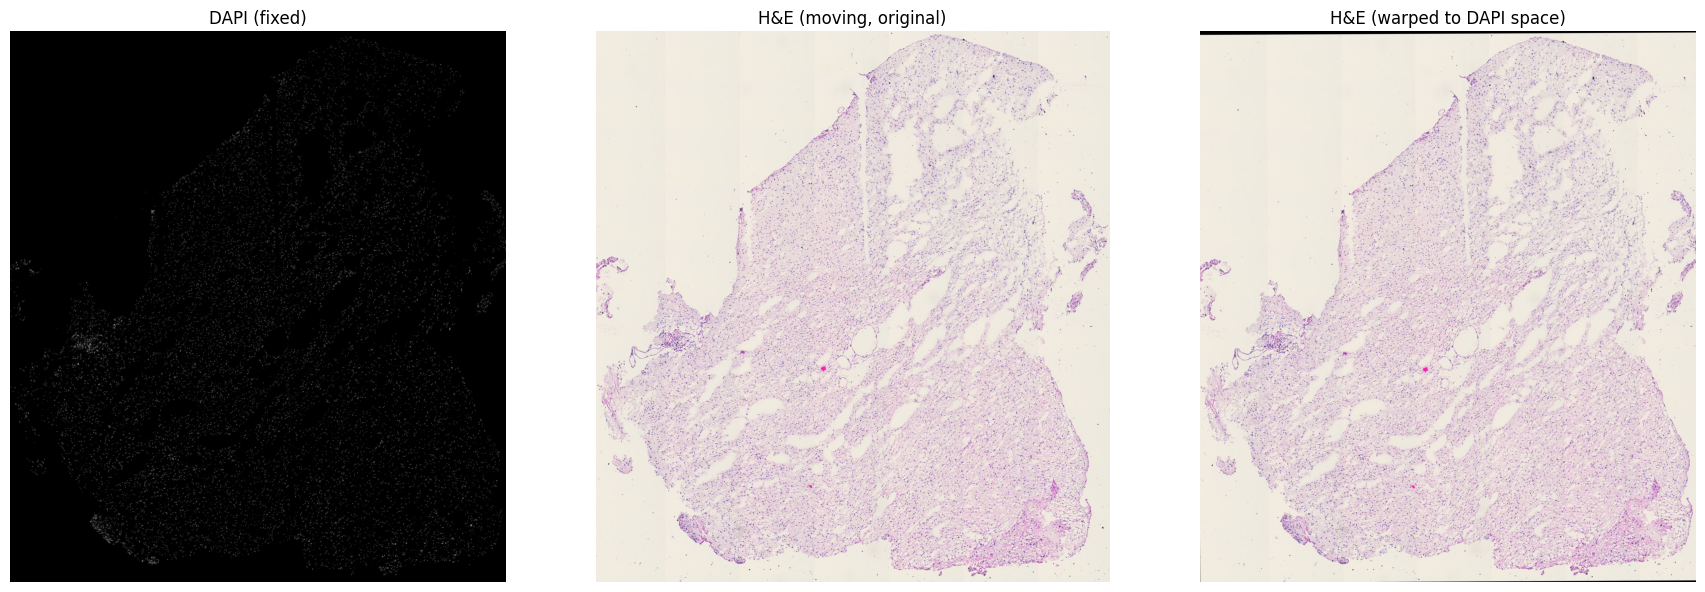

In [73]:
# Warp H&E RGB into DAPI space and do a quick visual check
# OpenCV warpPerspective requires all dimensions < SHRT_MAX (32767).
import matplotlib.pyplot as plt

SCALE = 1
dapi_vis_w = int(dapi_w * SCALE)
dapi_vis_h = int(dapi_h * SCALE)

# Scale matrix: S * H * S_inv maps scaled H&E -> scaled DAPI space
S = np.array([[SCALE, 0, 0],
              [0, SCALE, 0],
              [0,      0, 1]], dtype=np.float64)
S_inv = np.linalg.inv(S)
H_scaled = S @ H @ S_inv

he_rgb_warped = cv2.resize(he_rgb, (int(he_w * SCALE), int(he_h * SCALE)))

he_warped = cv2.warpPerspective(he_rgb_warped, H_scaled, (dapi_vis_w, dapi_vis_h))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(dapi_norm, cmap="gray")
axes[0].set_title("DAPI (fixed)")
axes[1].imshow(he_rgb_warped)
axes[1].set_title("H&E (moving, original)")
axes[2].imshow(he_warped)
axes[2].set_title("H&E (warped to DAPI space)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [74]:
tifffile.imwrite("IDHO03_HE_warped_to_DAPI.ome.tif", he_warped)